# FiPy による Davies 移流ベンチマーク

周期区間 $0 \le z < 1$ で、保存形の移流方程式 $\partial_t n + \partial_z(vn)=0$ を解きます。速度は $v(z)=1+9\sin^8(\pi z)$、初期値は区間 $[0.05,0.25]$ の高さ 1 の矩形パルスです。Davies ベンチマークの純移流ケース（$D=0$）を対象にします。

FiPy の一次風上法と Van Leer 法を同じ周期格子・時間刻みで実行し、パルスが速度場を一周する時間 $T$ の $0.4T$ と $T$ で参照解と比較します。両方式とも FiPy の陽的更新を使います。Van Leer の流束補正には実際の刻み幅が入り、元の NumPy ベンチマークの Heun 法とは時間更新が異なります。

必要なパッケージは FiPy、NumPy、Matplotlib です。参照解を含めて、この Notebook 単体で実行できます。

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from fipy import (
    CellVariable, ExplicitUpwindConvectionTerm, FaceVariable,
    PeriodicGrid1D, TransientTerm, VanLeerConvectionTerm,
)

CELLS = 1000
CFL = 0.2  # 元の設定と刻み幅を揃える場合は 0.01 に変更（実行時間が増加）
FRACTIONS = (0.4, 1.0)
REFERENCE_POINTS = 262145

## 特性曲線から求める参照セル平均

移動時間座標 $\tau(z)=\int_0^z v(s)^{-1}\,ds$ を台形則で表にします。各セルの両端から特性曲線を逆にたどり、出発点間の初期粒子数をセル幅で割ります。逆追跡が周期境界をまたぐ場合は、初期分布の積分に一周分の粒子数を加減します。

In [6]:
def velocity(z):
    return 1.0 + 9.0 * np.sin(np.pi * z)**8


def initial_mass(z):
    return np.clip(z - 0.05, 0.0, 0.20)


reference_z = np.linspace(0.0, 1.0, REFERENCE_POINTS)
inverse_speed = 1.0 / velocity(reference_z)
tau = np.r_[0.0, np.cumsum(
    0.5 * (inverse_speed[:-1] + inverse_speed[1:]) * np.diff(reference_z)
)]
period = tau[-1]


def reference_averages(edges, time):
    phase = np.interp(edges, reference_z, tau) - time
    turns = np.floor(phase / period)
    origin = np.interp(phase % period, tau, reference_z)
    cumulative_mass = initial_mass(origin) + 0.20 * turns
    return np.diff(cumulative_mass) / np.diff(edges)

## FiPy で時間発展

周期面を含む FiPy の面座標で速度を評価します。旧時刻のセル値を各ステップで保存し、比較時刻の直前では刻みを短縮します。

In [7]:
edges = np.linspace(0.0, 1.0, CELLS + 1)
widths = np.diff(edges)
mesh = PeriodicGrid1D(dx=1.0 / CELLS, nx=CELLS)
face_velocity = FaceVariable(
    mesh=mesh, rank=1, value=velocity(np.asarray(mesh.faceCenters))
)
initial_density = np.diff(initial_mass(edges)) / widths
initial_total = np.dot(widths, initial_density)
nominal_dt = CFL / (10.0 * CELLS)


def solve(convection_term):
    density = CellVariable(mesh=mesh, value=initial_density, hasOld=True)
    equation = TransientTerm() == -convection_term(coeff=face_velocity)
    time = 0.0
    steps = 0
    minimum = float(density.value.min())
    mass_error = 0.0
    snapshots = {}
    for fraction in FRACTIONS:
        target = fraction * period
        while time < target:
            remaining = target - time
            dt = min(nominal_dt, remaining)
            density.updateOld()
            equation.solve(var=density, dt=dt)
            values = density.value
            if not np.all(np.isfinite(values)):
                raise FloatingPointError("非有限の密度が発生しました")
            minimum = min(minimum, float(values.min()))
            mass_error = max(mass_error, abs(np.dot(widths, values) - initial_total))
            time = target if dt == remaining else time + dt
            steps += 1
        snapshots[fraction] = (density.value.copy(), minimum, mass_error, steps)
    return snapshots


schemes = {
    "First-order upwind": ExplicitUpwindConvectionTerm,
    "Van Leer": VanLeerConvectionTerm,
}
results = {name: solve(term) for name, term in schemes.items()}

## 誤差と粒子数

$L^1$ 誤差は、セル平均の絶対誤差をセル幅で積分した値です。最小密度と最大絶対質量誤差は、各比較時刻までの全ステップから求めます。速度が場所によって変わるため、密度の最大値は物理的にも変化します。分布のピークは参照解と比較します。

T = 0.59069649, initial mass = 0.20000000, dt <= 2.000e-05
 t/T  scheme                steps     L1 error   min density  max mass err
 0.4  First-order upwind    11814   2.5294e-02    0.0000e+00    8.8929e-14
 0.4  Van Leer              11814   4.9107e-03    0.0000e+00    8.9290e-14
 1.0  First-order upwind    29535   4.2819e-02    0.0000e+00    2.2193e-13
 1.0  Van Leer              29535   7.7544e-03    0.0000e+00    2.2166e-13


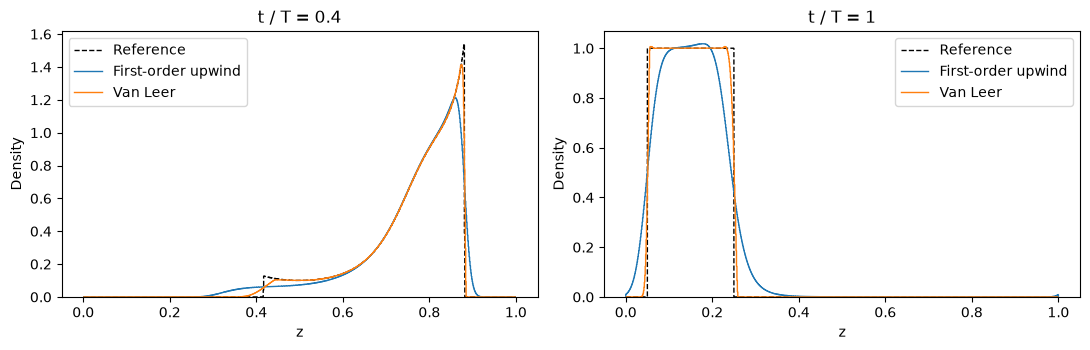

In [8]:
print(f"T = {period:.8f}, initial mass = {initial_total:.8f}, dt <= {nominal_dt:.3e}")
print(f"{'t/T':>4}  {'scheme':<20} {'steps':>6} {'L1 error':>12} {'min density':>13} {'max mass err':>13}")
fig, axes = plt.subplots(1, len(FRACTIONS), figsize=(11, 3.6), squeeze=False)
for ax, fraction in zip(axes[0], FRACTIONS):
    exact = reference_averages(edges, fraction * period)
    np.testing.assert_allclose(np.dot(widths, exact), initial_total, atol=1e-12, rtol=0)
    ax.stairs(exact, edges, color="black", linestyle="--", label="Reference")
    for name, snapshots in results.items():
        density, minimum, mass_error, steps = snapshots[fraction]
        error = np.dot(widths, np.abs(density - exact))
        print(f"{fraction:4.1f}  {name:<20} {steps:6d} {error:12.4e} "
              f"{minimum:13.4e} {mass_error:13.4e}")
        ax.stairs(density, edges, label=name)
    ax.set(xlabel="z", ylabel="Density", title=f"t / T = {fraction:g}")
    ax.legend()
fig.tight_layout()
plt.show()